# Task 1: Multi-Class Benchmark Classification Pipeline (Iris)

**Goal:** build an end-to-end classification pipeline on the Iris dataset: exploratory pairplots, feature scaling with `StandardScaler`, an 80/20 train/test split, Logistic Regression and Decision Tree models, and a benchmark of accuracy, precision, recall and F1-score with confusion matrix heatmaps and decision boundary plots.

**Dataset:** `iris.csv` (seaborn-data). Place it next to this notebook, or the notebook downloads it automatically.

## 1. Imports and settings

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42

## 2. Load the dataset with Pandas

In [2]:
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv("iris.csv") if os.path.exists("iris.csv") else pd.read_csv(URL)
print("Shape:", df.shape)
df.head()

Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Exploratory data analysis

In [3]:
df.info()
print()
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Class distribution:")
print(df["species"].value_counts())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


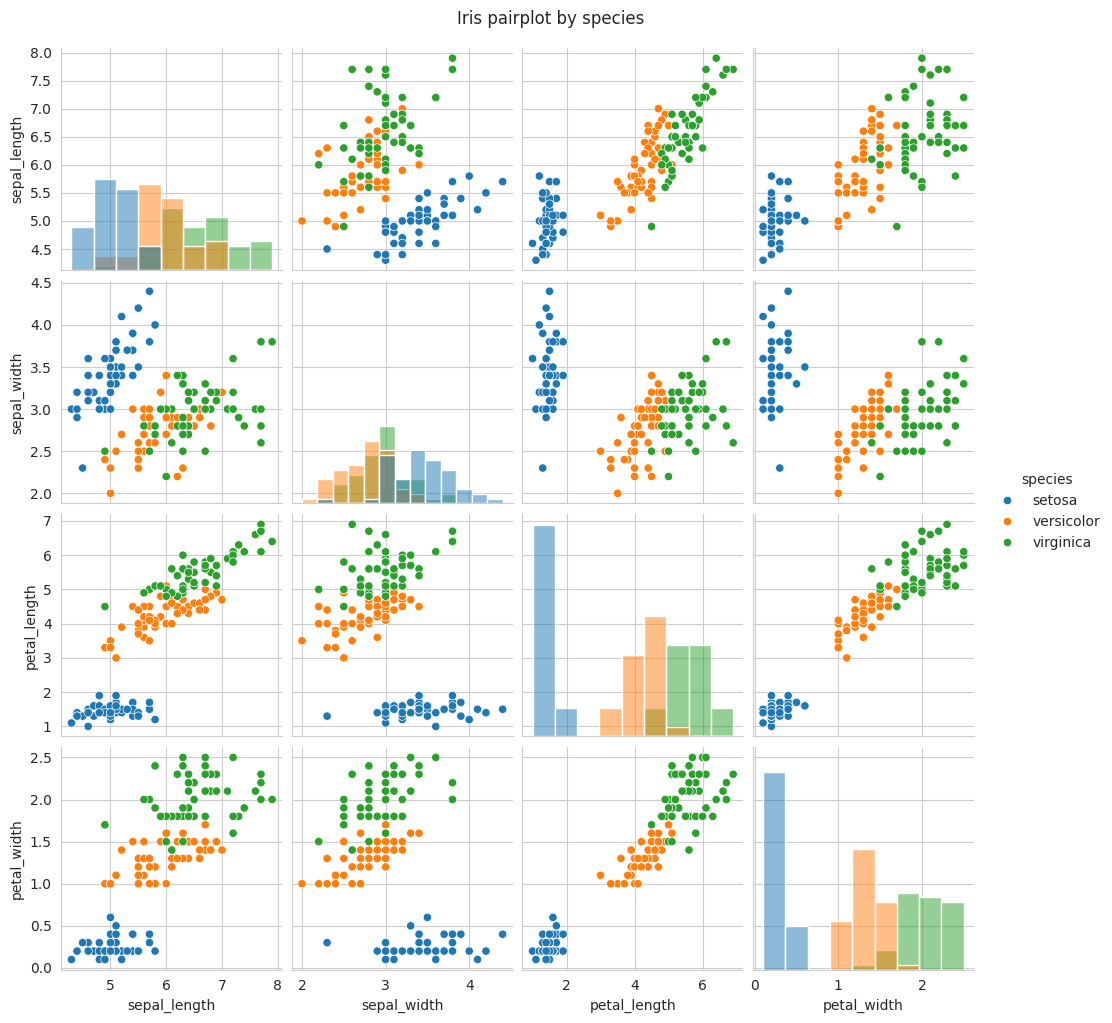

In [4]:
# Exploratory pairplot (Seaborn)
sns.pairplot(df, hue="species", diag_kind="hist", corner=False)
plt.suptitle("Iris pairplot by species", y=1.02)
plt.show()

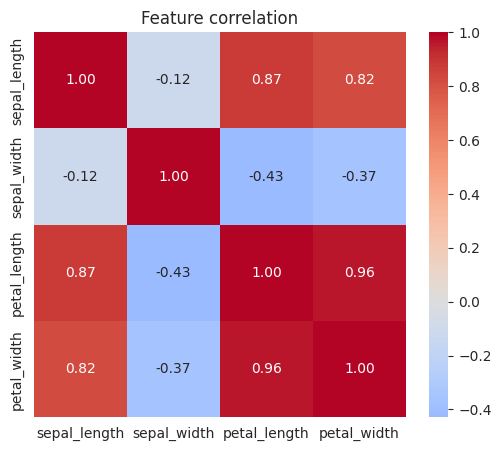

In [5]:
# Correlation heatmap of the four measurements
plt.figure(figsize=(6, 5))
sns.heatmap(df.drop(columns="species").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature correlation")
plt.show()

Observations: the three classes are balanced (50 each). Setosa is clearly separable from the other two, while versicolor and virginica overlap slightly, especially in sepal measurements. Petal length and petal width separate the classes best.

## 4. Features, target and 80/20 train/test split

In [6]:
X = df.drop(columns="species")
y = df["species"]

# stratify keeps the class proportions equal in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print()
print("Train class counts:")
print(y_train.value_counts())
print()
print("Test class counts:")
print(y_test.value_counts())

Train: (120, 4)  Test: (30, 4)

Train class counts:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Test class counts:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


## 5. Feature scaling with StandardScaler

The scaler is fit on the **training data only** and then applied to the test data, so no information from the test set leaks into training.

In [7]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train mean after scaling (about 0):", X_train_s.mean(axis=0).round(3))
print("Train std after scaling (about 1): ", X_train_s.std(axis=0).round(3))

Train mean after scaling (about 0): [-0.  0.  0.  0.]
Train std after scaling (about 1):  [1. 1. 1. 1.]


## 6. Train Logistic Regression and Decision Tree

In [8]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)

log_reg.fit(X_train_s, y_train)
tree.fit(X_train_s, y_train)

models = {"Logistic Regression": log_reg, "Decision Tree": tree}
print("Both models trained.")

Both models trained.


## 7. Evaluation: accuracy, precision, recall, F1-score

In [9]:
rows, preds = [], {}
for name, model in models.items():
    p = model.predict(X_test_s)
    preds[name] = p
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, p),
        "Precision (macro)": precision_score(y_test, p, average="macro"),
        "Recall (macro)": recall_score(y_test, p, average="macro"),
        "F1-score (macro)": f1_score(y_test, p, average="macro"),
    })

results = pd.DataFrame(rows).set_index("Model")
display(results.round(4))

,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9667,0.9697,0.9667,0.9666


In [10]:
for name, p in preds.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, p, digits=3))

Logistic Regression
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

Decision Tree
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     0.900     0.947        10
   virginica      0.909     1.000     0.952        10

    accuracy                          0.967        30
   macro avg      0.970     0.967     0.967        30
weighted avg      0.970     0.967     0.967        30



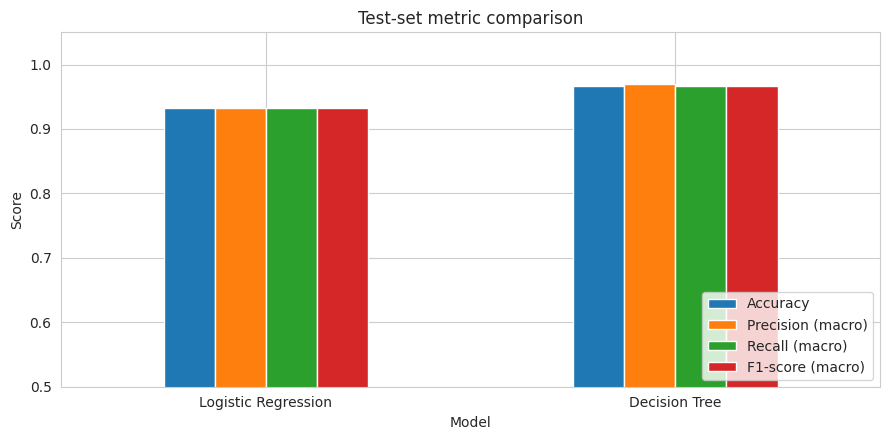

In [11]:
results.plot(kind="bar", figsize=(9, 4.5), ylim=(0.5, 1.05), rot=0)
plt.title("Test-set metric comparison")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 8. Confusion matrix heatmaps

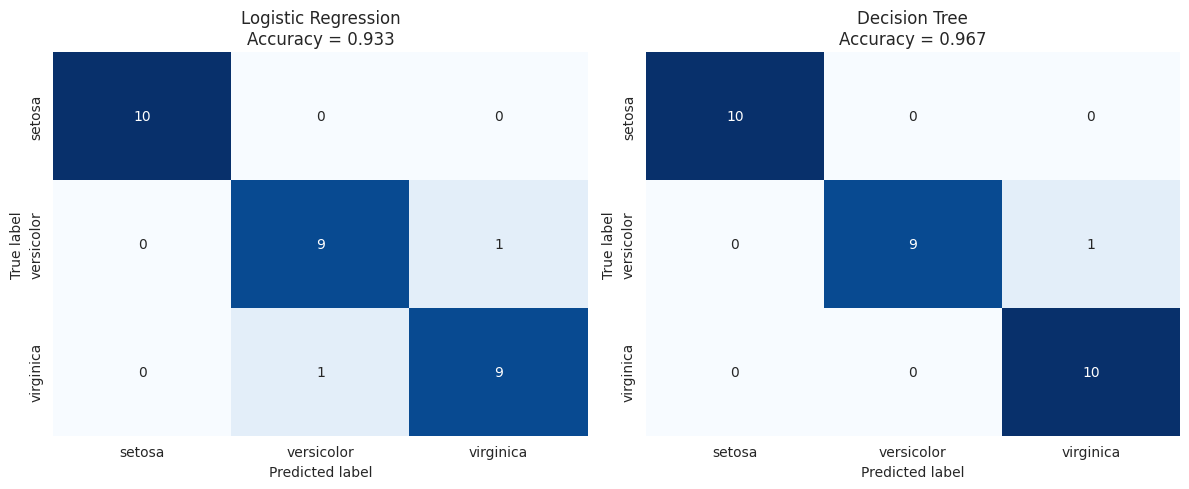

In [12]:
class_names = sorted(y.unique())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p, labels=class_names)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f"{name}\nAccuracy = {accuracy_score(y_test, p):.3f}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
plt.tight_layout()
plt.show()

## 9. Cross-validation (robustness check)

With only 30 test samples, one test split is a noisy estimate. 5-fold stratified cross-validation on the full data gives a more reliable comparison. A scaler inside a pipeline is refit on each training fold.

In [13]:
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in [("Logistic Regression", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
                    ("Decision Tree", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))]:
    pipe = make_pipeline(StandardScaler(), model)
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy")
    cv_rows.append({"Model": name, "Mean CV accuracy": scores.mean(), "Std": scores.std()})

display(pd.DataFrame(cv_rows).set_index("Model").round(4))

,Mean CV accuracy,Std
Model,,
Logistic Regression,0.9533,0.0452
Decision Tree,0.9600,0.0249


## 10. Decision boundary visualization

Decision boundaries can only be drawn in 2D, so we retrain both models on the two most informative features, **petal length** and **petal width** (scaled), and colour the plane by the predicted class.

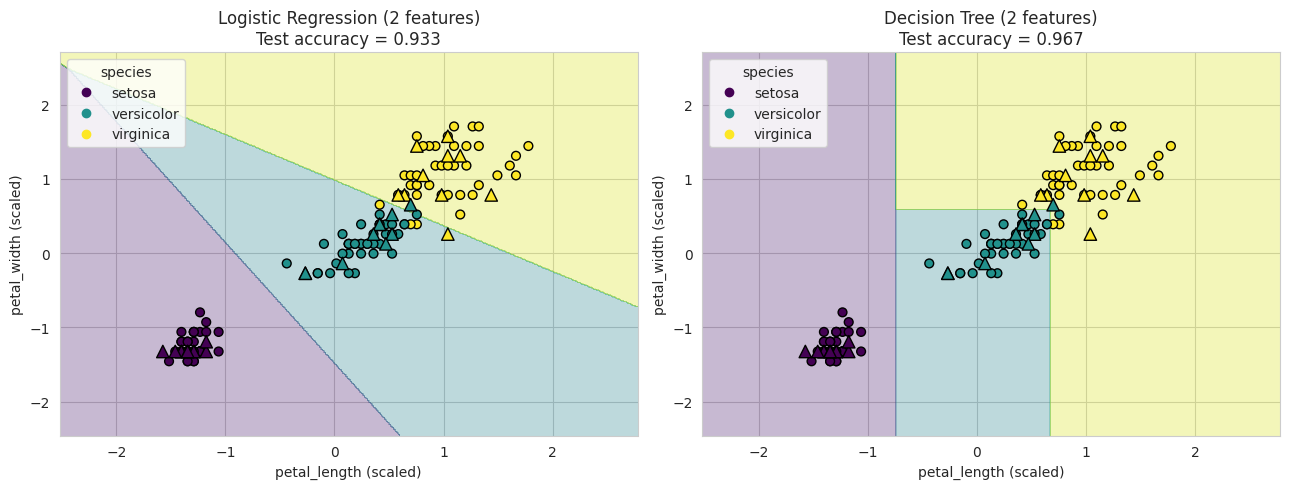

In [14]:
feat2 = ["petal_length", "petal_width"]
le = LabelEncoder()
y_num = le.fit_transform(y)

X2_train, X2_test, y2_train, y2_test = train_test_split(
    df[feat2], y_num, test_size=0.2, random_state=RANDOM_STATE, stratify=y_num
)
sc2 = StandardScaler().fit(X2_train)
X2_train_s, X2_test_s = sc2.transform(X2_train), sc2.transform(X2_test)

models2 = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
}

x_min, x_max = X2_train_s[:, 0].min() - 1, X2_train_s[:, 0].max() + 1
y_min, y_max = X2_train_s[:, 1].min() - 1, X2_train_s[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, m) in zip(axes, models2.items()):
    m.fit(X2_train_s, y2_train)
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
    sc_train = ax.scatter(X2_train_s[:, 0], X2_train_s[:, 1], c=y2_train, cmap="viridis",
                          edgecolor="k", s=40, label="train")
    ax.scatter(X2_test_s[:, 0], X2_test_s[:, 1], c=y2_test, cmap="viridis",
               edgecolor="k", marker="^", s=80, label="test")
    acc = accuracy_score(y2_test, m.predict(X2_test_s))
    ax.set_title(f"{name} (2 features)\nTest accuracy = {acc:.3f}")
    ax.set_xlabel("petal_length (scaled)")
    ax.set_ylabel("petal_width (scaled)")
    handles = sc_train.legend_elements()[0]
    ax.legend(handles, list(le.classes_), title="species", loc="upper left")
plt.tight_layout()
plt.show()

## 11. Extra: learned decision tree and feature importance

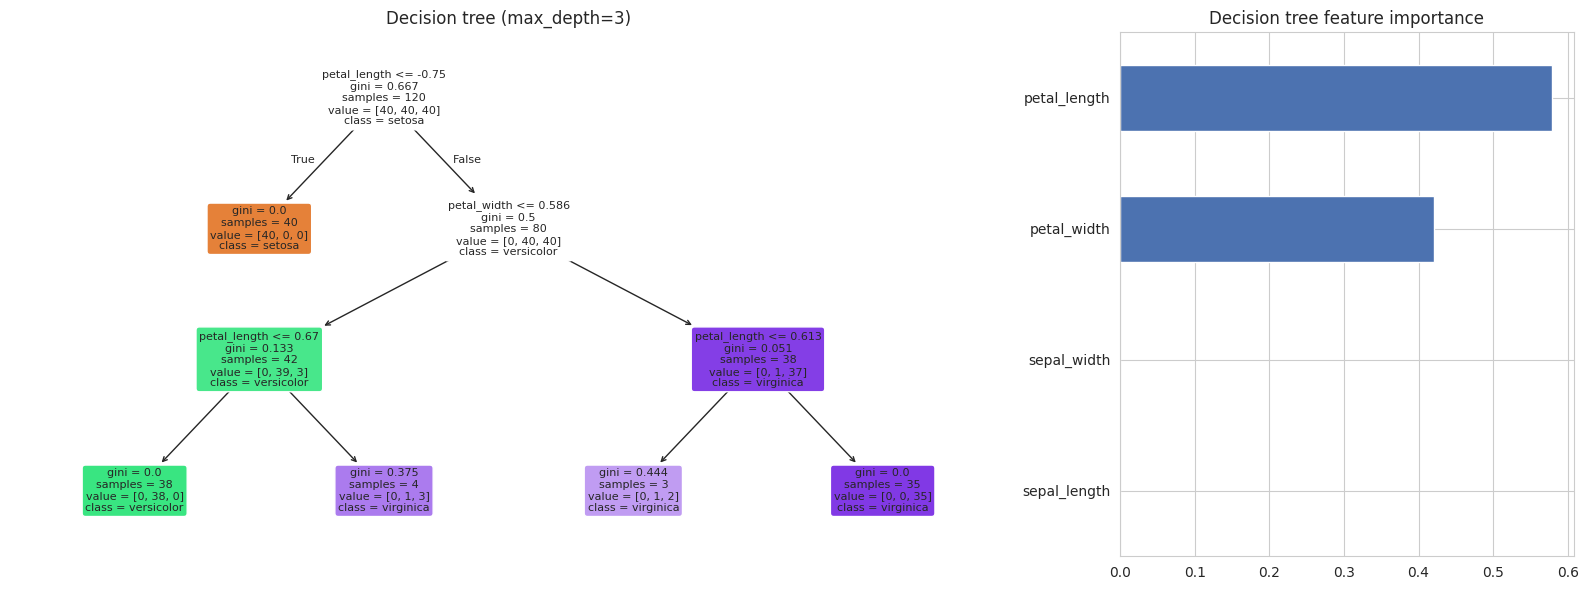

Logistic Regression coefficients (per class, standardized features):


,sepal_length,sepal_width,petal_length,petal_width
setosa,-1.089,1.024,-1.799,-1.686
versicolor,0.536,-0.360,-0.204,-0.808
virginica,0.553,-0.664,2.003,2.494


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [2.2, 1]})
plot_tree(tree, feature_names=list(X.columns), class_names=list(tree.classes_),
          filled=True, rounded=True, fontsize=8, ax=axes[0])
axes[0].set_title("Decision tree (max_depth=3)")

imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", ax=axes[1], color="#4C72B0")
axes[1].set_title("Decision tree feature importance")
plt.tight_layout()
plt.show()

coef = pd.DataFrame(log_reg.coef_, index=log_reg.classes_, columns=X.columns)
print("Logistic Regression coefficients (per class, standardized features):")
display(coef.round(3))

## 12. Conclusion

**Test-set results (80/20 split, 30 test samples)**

| Model | Accuracy | Precision (macro) | Recall (macro) | F1-score (macro) |
|---|---|---|---|---|
| Logistic Regression | 0.933 | 0.933 | 0.933 | 0.933 |
| Decision Tree | 0.967 | 0.970 | 0.967 | 0.967 |

**5-fold cross-validation accuracy:** Logistic Regression = 0.9533 (std 0.0452), Decision Tree = 0.9600 (std 0.0249).

**Observations**
- Both models classify Iris very well. The Decision Tree achieved the best test accuracy (0.967, i.e. 29 of 30 correct) compared with 0.933 (28 of 30) for Logistic Regression.
- Setosa is classified perfectly by both models (precision, recall and F1 all 1.000). The errors occur between versicolor and virginica, as the confusion matrices show, because these two classes overlap slightly.
- Logistic Regression made 2 mistakes, while the Decision Tree made only 1 (a versicolor predicted as virginica).
- Logistic Regression draws smooth linear boundaries, while the Decision Tree draws axis-aligned rectangular regions, as seen in the decision boundary plots.
- Petal length and petal width are the most important features for both models. The pairplot shows they separate the three species best.
- The test set has only 30 samples, so one extra mistake changes accuracy by about 3.3%. Cross-validation gives a fairer comparison: the two models are very close (0.953 vs 0.960), and the Decision Tree is also more stable across folds (lower standard deviation).
- StandardScaler matters for Logistic Regression, which is regularized and gradient-based, but not for the Decision Tree, which is scale-invariant. It was applied to both to follow the pipeline. The scaler was fit on the training data only, to avoid data leakage.

**Conclusion:** Both models are suitable for this dataset, and the difference between them is small. Logistic Regression is simple and gives smooth boundaries. The Decision Tree scored slightly higher on the test split and in cross-validation, and it is easy to interpret, but it can overfit if it grows deeper (here max_depth = 3 was used).